# Практическая работа № 3
## Прикладные дифференциальные уравнения

По заданиям файла «Практические занятия Листок 3 (2).pdf», составитель: проф. П. Е. Рябов.
Оформление по образцу `Prac1.ipynb` и `Prac2.ipynb`: сначала теория, затем решения с вычислениями и рисунками.

**Зависимости:** `numpy`, `scipy`, `sympy`, `matplotlib`, `IPython`.
При необходимости: `%pip install numpy scipy sympy matplotlib ipython`.
Запускайте ячейки сверху вниз. PNG сохраняются в `output/prac3`.
Анимации встроены в ноутбук и дополнительно сохраняются в HTML с кнопками воспроизведения,
паузы, ползунком времени и выбором скорости. Для просмотра отдельного HTML сервер и FFmpeg не нужны.

## Теория

### 1. Материальная точка на гладкой кривой

Считаем связи идеальными, трение и сопротивление воздуха отсутствуют.
В вертикальной плоскости ось $y$ направлена вверх:
$$m\ddot{\mathbf r}=-mg\mathbf e_y+\mathbf N,\qquad
\mathbf N\cdot\dot{\mathbf r}=0.$$
Скалярное умножение на скорость исключает реакцию:
$$\frac{d}{dt}\left(\frac{m|\dot{\mathbf r}|^2}{2}+mgy\right)=0.$$
Здесь $g=9.81\ \text{м/с}^2$. **Постоянная вертикальная скорость**
$\dot y=-c$ не означает постоянную полную скорость.

### 2. Прямоугольный бильярд, развёртка и тор

Внутри $[0,a]\times[0,b]$ точка движется свободно:
$$\ddot x=\ddot y=0.$$
На вертикальной стенке $v_x\mapsto-v_x$, на горизонтальной $v_y\mapsto-v_y$.
Кинетическая энергия сохраняется. В развёртке отражения заменяют зеркальным
отражением прямоугольника, и траектория становится прямой
$X=x_0+v_xt$, $Y=y_0+v_yt$.

Свёртка прямой в прямоугольник задаётся треугольной волной
$$F_L(q)=L-|((q\bmod 2L)-L)|,\qquad x=F_a(X),\quad y=F_b(Y).$$
Развёрнутое движение по модулю $(2a,2b)$ есть линейный поток на торе.
При $v_xv_y\ne0$ орбита периодична тогда и только тогда, когда
$$r=\frac{av_y}{bv_x}\in\mathbb Q.$$
При иррациональном $r$ поток на торе плотен и равномерно распределён
относительно равномерной меры; его проекция заполняет прямоугольник.
Эргодичность относится к потоку **при фиксированном направлении на торе**:
полная бильярдная система на всей поверхности энергии не эргодична,
так как сохраняются $|v_x|$ и $|v_y|$. Точное попадание в вершину
для идеального бильярда является особым случаем с неопределённым законом отражения.
В примерах такие попадания исключены.

Гамильтониан в области свободного движения:
$$H=\frac{p_x^2+p_y^2}{2m},\quad
\dot x=\frac{p_x}{m},\ \dot y=\frac{p_y}{m},\ \dot p_x=\dot p_y=0.$$
На границах отражается нормальная компонента импульса. На торе
$p_x,p_y$ постоянны; это интегрируемая система.

### 3. Равновесие тяжёлой нити

Пусть $\mu$ - постоянная линейная плотность, $s$ - длина дуги.
Для гибкой нерастяжимой нити натяжение направлено по касательной.
Его горизонтальная составляющая $H>0$ постоянна, а вертикальная $V$ удовлетворяет
$$dV=\mu g\,ds,\quad V=Hy',\quad ds=\sqrt{1+y'^2}\,dx.$$
Поэтому $Hy''=\mu g\sqrt{1+y'^2}$. Введём
$$a=\frac{H}{\mu g}>0.$$
Общее решение: $y=a\cosh((x-x_c)/a)+C$. Чем больше $a$,
тем меньше провисание при одинаковых опорах.

### 4. Таутохрона и уравнение Абеля

Точка начинает движение **из состояния покоя** на высоте $h$ над нижней точкой.
На одной монотонной ветви $s(y)$ - длина дуги от нижней точки.
Из энергии $v=\sqrt{2g(h-y)}$, откуда
$$T(h)=\frac1{\sqrt{2g}}\int_0^h\frac{s'(y)}{\sqrt{h-y}}\,dy.$$
Требование $T(h)=T_0$ даёт интегральное уравнение Абеля.
Его решение приводит к $y\propto s^2$ и гармоническому движению по дуге,
хотя зависимость декартовых координат от времени нелинейна.

### 5. Математический маятник

Для длины $\ell$ и угла $\theta$ от нижней вертикали:
$$\ddot\theta+\frac g\ell\sin\theta=0,\qquad
E=\frac{m\ell^2\dot\theta^2}{2}+mg\ell(1-\cos\theta).$$
При малых углах $\sin\theta\approx\theta$, частота
$\omega_0=\sqrt{g/\ell}$, период $T_{\rm lin}=2\pi\sqrt{\ell/g}$.
Для нелинейных колебаний из покоя с амплитудой $A<\pi$:
$$T(A)=4\sqrt{\ell/g}\,K(k^2),\qquad k=\sin(A/2),$$
$$K(m)=\int_0^{\pi/2}\frac{d\varphi}{\sqrt{1-m\sin^2\varphi}}.$$
В `scipy.special.ellipk` передаётся параметр $m=k^2$, а не модуль $k$.
При $A\to\pi$ период стремится к бесконечности. На фазовой плоскости
уровень $E=2mg\ell$ является сепаратрисой между колебаниями и вращениями.

## Решения задач

### Подключение библиотек и сохранение результатов

In [1]:
from pathlib import Path
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from scipy.integrate import solve_ivp, quad
from scipy.special import ellipk, ellipj
from IPython.display import display, HTML

g = 9.81
OUT = Path('output/prac3')
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 90, 'font.size': 10,
                     'animation.embed_limit': 80})

def finish_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()

def show_animation(fig, update, frames, name, interval=60):
    # JSHTML содержит кадры и готовые элементы управления Jupyter.
    animation = FuncAnimation(fig, update, frames=frames, interval=interval,
                              blit=False, repeat=True)
    html = animation.to_jshtml(default_mode='once')
    (OUT / f'{name}.html').write_text(html, encoding='utf-8')
    plt.close(fig)
    display(HTML(html))
    return animation

### 3.1. Задача о равномерном спуске

Требуется $\dot y=-c$, $c>0$, то есть $y=y_0-ct$, $\ddot y=0$.
Обозначим $u=\dot x>0$, $u(0)=u_0>0$. Проекция закона Ньютона на скорость:
$$m(\ddot x\dot x+\ddot y\dot y)=-mg\dot y
\quad\Longrightarrow\quad u\dot u=gc.$$
Реакция исключена благодаря её ортогональности скорости.
Интегрируем с начальным условием:
$$u^2=u_0^2+2gct,\qquad
x=x_0+\frac{(u_0^2+2gct)^{3/2}-u_0^3}{3gc}.$$
Исключая время, получаем явный вид кривой:
$$\boxed{y(x)=y_0+\frac{u_0^2}{2g}
-\frac{[u_0^3+3gc(x-x_0)]^{2/3}}{2g}.}$$
Берём ветвь $x\ge x_0$ при движении $t\ge0$. Зеркальная относительно
вертикали ветвь получается при отрицательной горизонтальной скорости.
В сдвинутых координатах это полукубическая парабола:
$$[u_0^3+3gc(x-x_0)]^2=[u_0^2+2g(y_0-y)]^3.$$

**Дифференциальное уравнение кривой.** Пусть $p=y'$, тогда
$\dot x=-c/p$, $\ddot x=-c^2y''/p^3$. Подстановка в
$\ddot x\dot x=gc$ даёт
$$\boxed{y''=\frac{g}{c^2}(y')^4.}$$
После разделения переменных $p^{-4}dp=(g/c^2)dx$ получаем
$p^{-3}=C_1-3gx/c^2$; второе интегрирование даёт приведённую выше кривую.

Начальная скорость обязана иметь вертикальную компоненту $-c$:
это не спуск из покоя. При $u_0=0$ требовалось бы бесконечное
горизонтальное ускорение в начальный момент, поэтому этот особый случай
не используется. Проверка реакции: $N_y=mg$,
$N_x=m\ddot x=mgc/u$, следовательно $\mathbf N\cdot(u,-c)=0$.
Полная скорость $\sqrt{u^2+c^2}$ возрастает, а вертикальная остаётся постоянной.

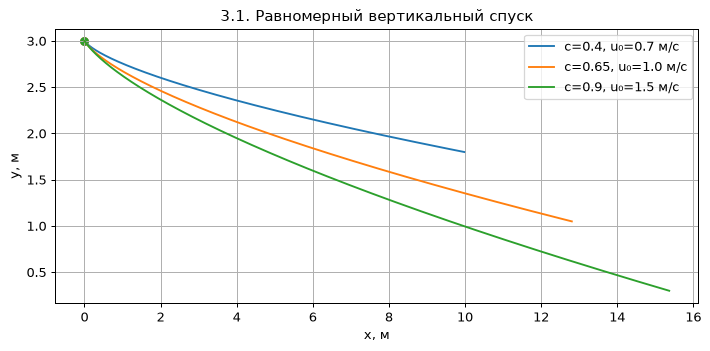

In [2]:
# 3.1. Семейство траекторий для разных начальных скоростей
def descent(t, c=0.65, u0=1.0, x0=0.0, y0=3.0):
    t = np.asarray(t)
    u = np.sqrt(u0*u0 + 2*g*c*t)
    x = x0 + (u**3-u0**3)/(3*g*c)
    y = y0-c*t
    return x, y, u

t1 = np.linspace(0, 3.0, 350)
fig, ax = plt.subplots(figsize=(8, 4))
for c, u0 in [(0.4, 0.7), (0.65, 1.0), (0.9, 1.5)]:
    x, y, u = descent(t1, c, u0)
    ax.plot(x, y, label=f'c={c}, u₀={u0} м/с')
    ax.scatter(x[0], y[0], s=35)
    explicit_y = 3 + u0*u0/(2*g)-(u0**3+3*g*c*x)**(2/3)/(2*g)
    assert np.allclose(y, explicit_y)
    assert np.allclose((u*u+c*c)/2+g*y, (u0*u0+c*c)/2+3*g)
ax.set(xlabel='x, м', ylabel='y, м', title='3.1. Равномерный вертикальный спуск')
ax.grid(); ax.legend()
finish_figure(fig, '3_1_descent')

fig, ax = plt.subplots(figsize=(7, 4))
x1, y1, u1 = descent(t1)
ax.plot(x1, y1, color='0.6', label='Траектория')
ball1, = ax.plot([], [], 'o', color='crimson', ms=9)
trail1, = ax.plot([], [], color='crimson', lw=2)
info1 = ax.text(0.02, 0.95, '', transform=ax.transAxes, va='top')
ax.set(xlim=(-0.3, x1[-1]+0.4), ylim=(0.8, 3.5), xlabel='x, м', ylabel='y, м')
ax.set_title('3.1. Постоянная вертикальная скорость'); ax.grid()
fig.tight_layout()
def update1(k):
    ball1.set_data([x1[k]], [y1[k]])
    trail1.set_data(x1[:k+1], y1[:k+1])
    info1.set_text(f't={t1[k]:.2f} с; vᵧ=−0.65 м/с\nvₓ={u1[k]:.2f} м/с; |v|={np.hypot(u1[k],0.65):.2f} м/с')
anim1 = show_animation(fig, update1, np.linspace(0, len(t1)-1, 65, dtype=int), '3_1_descent')

### 3.2. Бильярд в прямоугольнике

Пусть $a=3$, $b=2$, начальная точка $(x_0,y_0)=(0.63,0.57)$.
Используем точную свёртку $F_L$ из теории, поэтому численный шаг
не влияет на закон отражения и накопления ошибки при ударах нет.

Если $r=p/q$ в несократимом виде, то за период развёрнутая точка
должна пройти $2aq$ по горизонтали и $2bp$ по вертикали:
$$T=\frac{2aq}{|v_x|}=\frac{2b|p|}{|v_y|}.$$
При $r=2/3$, $v_x=1$, $v_y=4/9$ получаем $T=18$ с.
При $r=\sqrt2$, $v_y=2\sqrt2/3$ периода нет; конечный рисунок
демонстрирует только часть плотной бесконечной орбиты.
Если одна из компонент скорости равна нулю, движение периодично вдоль отрезка
с периодом $2a/|v_x|$ или $2b/|v_y|$; неподвижная точка выделяется отдельно.

В анимации сравниваем оба случая в прямоугольнике и на торе.
Углы тора $\alpha=\pi X/a$, $\beta=\pi Y/b$ берутся по модулю $2\pi$.
Вложение в трёхмерное пространство:
$$((R+r_0\cos\beta)\cos\alpha,
(R+r_0\cos\beta)\sin\alpha,r_0\sin\beta).$$
Трёхмерный тор служит наглядной моделью; прямолинейным поток является
в его угловых координатах, а не в пространстве $\mathbb R^3$.

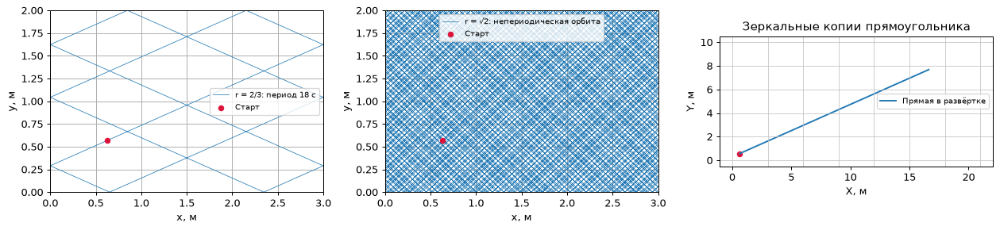

In [3]:
# 3.2. Точная развёртка и свёртка
a2, b2, x02, y02 = 3.0, 2.0, 0.63, 0.57
ratios = [2/3, np.sqrt(2)]
vys = [b2/a2*r for r in ratios]
def fold(q, L):
    return L-np.abs(np.mod(q, 2*L)-L)
def billiard(t, vy):
    return fold(x02+np.asarray(t), a2), fold(y02+vy*np.asarray(t), b2)
def torus(t, vy):
    alpha = np.pi*(x02+np.asarray(t))/a2
    beta = np.pi*(y02+vy*np.asarray(t))/b2
    return ((2+0.65*np.cos(beta))*np.cos(alpha),
            (2+0.65*np.cos(beta))*np.sin(alpha), 0.65*np.sin(beta))

assert np.allclose(billiard(0, vys[0]), billiard(18, vys[0]))
assert np.isclose(1+vys[0]**2, 1+(-vys[0])**2)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, vy, end, label in zip(axes[:2], vys, [18, 450], ['r = 2/3: период 18 с', 'r = √2: непериодическая орбита']):
    tt = np.linspace(0, end, int(end*150))
    xx, yy = billiard(tt, vy)
    ax.plot(xx, yy, lw=0.6, label=label)
    ax.scatter([x02], [y02], c='crimson', s=25, zorder=3, label='Старт')
    ax.set(xlim=(0,a2), ylim=(0,b2), xlabel='x, м', ylabel='y, м')
    ax.set_aspect('equal'); ax.grid(); ax.legend(fontsize=8)
ax = axes[2]
tt = np.linspace(0, 16, 1500)
ax.plot(x02+tt, y02+vys[0]*tt, label='Прямая в развёртке')
for xx in np.arange(0, 22, a2): ax.axvline(xx, color='0.75', lw=0.6)
for yy in np.arange(0, 12, b2): ax.axhline(yy, color='0.75', lw=0.6)
ax.scatter([x02], [y02], c='crimson', s=25)
ax.set(xlabel='X, м', ylabel='Y, м', title='Зеркальные копии прямоугольника')
ax.set_aspect('equal'); ax.legend(fontsize=8)
finish_figure(fig, '3_2_billiard')

# Синхронно: прямоугольник, развёртка и тор для двух направлений
fig = plt.figure(figsize=(12, 7))
artists2 = []
aa, bb = np.meshgrid(np.linspace(0,2*np.pi,30), np.linspace(0,2*np.pi,18))
surface2 = ((2+0.65*np.cos(bb))*np.cos(aa), (2+0.65*np.cos(bb))*np.sin(aa), 0.65*np.sin(bb))
t2 = np.linspace(0, 18, 2500)
for row, (vy, title) in enumerate(zip(vys, ['Рациональное r=2/3', 'Иррациональное r=√2'])):
    ax = fig.add_subplot(2,3,3*row+1)
    ax.set(xlim=(0,a2), ylim=(0,b2), title=title, xlabel='x', ylabel='y')
    ax.grid(); line, = ax.plot([], [], lw=0.8); ball, = ax.plot([], [], 'ro', ms=6)
    au = fig.add_subplot(2,3,3*row+2)
    au.set(xlim=(0,20), ylim=(0,19), title='Развёртка', xlabel='X', ylabel='Y')
    for xx in np.arange(0,21,a2): au.axvline(xx,color='0.8',lw=0.5)
    for yy in np.arange(0,20,b2): au.axhline(yy,color='0.8',lw=0.5)
    lu, = au.plot([], [], lw=1); bu, = au.plot([], [], 'ro', ms=5)
    at = fig.add_subplot(2,3,3*row+3, projection='3d')
    at.plot_wireframe(*surface2, rstride=3, cstride=3, color='0.7', linewidth=0.4, alpha=0.5)
    at.set(xlim=(-3,3),ylim=(-3,3),zlim=(-1,1),title='Поток на торе')
    at.set_box_aspect((3,3,1)); at.set_axis_off()
    lt, = at.plot([],[],[],lw=1); bt, = at.plot([],[],[],'ro',ms=5)
    artists2.append((vy,line,ball,lu,bu,lt,bt))
caption2 = fig.suptitle('')
fig.tight_layout(rect=(0,0,1,0.94))
def update2(k):
    ts = t2[:k+1]
    for vy,line,ball,lu,bu,lt,bt in artists2:
        xx,yy = billiard(ts,vy)
        line.set_data(xx,yy); ball.set_data([xx[-1]],[yy[-1]])
        lu.set_data(x02+ts,y02+vy*ts); bu.set_data([x02+ts[-1]],[y02+vy*ts[-1]])
        tx,ty,tz = torus(ts,vy)
        lt.set_data_3d(tx,ty,tz); bt.set_data_3d([tx[-1]],[ty[-1]],[tz[-1]])
    caption2.set_text(f'3.2. t={t2[k]:.2f} с; скорости |v| постоянны: {np.hypot(1,vys[0]):.3f} и {np.hypot(1,vys[1]):.3f} м/с')
anim2 = show_animation(fig, update2, np.linspace(0,len(t2)-1,65,dtype=int), '3_2_billiard')

### 3.3. Цепная линия

Из равновесия элемента цепи, согласно теории,
$$y''=\frac1a\sqrt{1+y'^2},\qquad a=\frac{H}{\mu g}.$$
Положим $p=y'$. Разделяя переменные, получим
$$\int\frac{dp}{\sqrt{1+p^2}}=\frac xa+C_1,
\quad\operatorname{arsinh}p=\frac{x-x_c}{a},
\quad p=\sinh\frac{x-x_c}{a}.$$
Ещё одно интегрирование даёт
$$\boxed{y=a\cosh\frac{x-x_c}{a}+C.}$$
Выбором начала координат $x_c=C=0$ получаем требуемый вид
$y=a\operatorname{ch}(x/a)$.

Для симметричных опор $(\pm d,h)$:
$$y(x)=h+a\left(\cosh\frac xa-\cosh\frac da\right),$$
$$f=h-y(0)=a(\cosh(d/a)-1),\qquad
L=2a\sinh(d/a),\qquad T(x)=H\cosh(x/a).$$
В нижней точке $T(0)=H$, у опор натяжение больше.
Если задана одна нерастяжимая цепь длины $L>2d$, параметр $a$
определяется уравнением длины, а не выбирается независимо.

Ниже анимация показывает **семейство статических равновесий** с одинаковыми
опорами и различными длинами: при изменении $H$ или $\mu$ меняется $a$ и
требуемая длина $L$. Это сравнение разных цепей, не динамика одной
нерастяжимой цепи. Для цепи фиксированной длины изменение плотности
само по себе меняет натяжение, но не геометрическую форму.

Для элемента между $x_-$ и $x_+$ силы на концах:
$$\mathbf T_-=(-H,-H\sinh(x_-/a)),\quad
\mathbf T_+=(H,H\sinh(x_+/a)),$$
$$\mathbf W=(0,-\mu ga[\sinh(x_+/a)-\sinh(x_-/a)]).$$
Их сумма равна нулю. В анимации стрелки сил имеют общий масштаб.

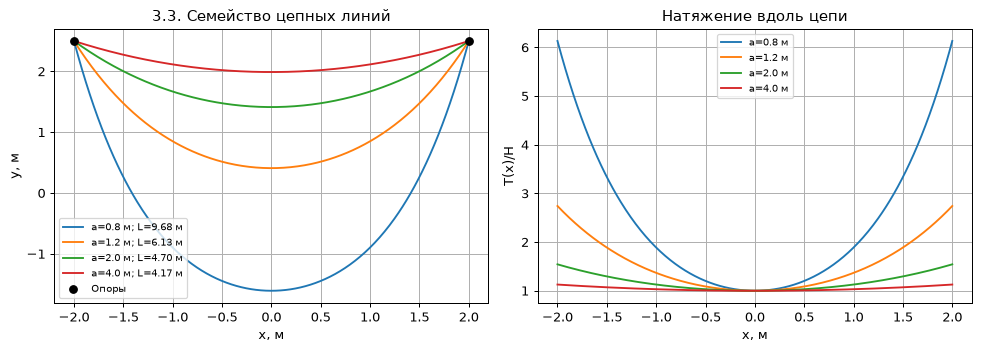

In [4]:
# 3.3. Форма, провисание и натяжение
d3, h3 = 2.0, 2.5
x3 = np.linspace(-d3, d3, 400)
def chain(x, a):
    return h3+a*(np.cosh(np.asarray(x)/a)-np.cosh(d3/a))
fig, axes = plt.subplots(1,2,figsize=(11,4))
for a in [0.8, 1.2, 2.0, 4.0]:
    axes[0].plot(x3, chain(x3,a), label=f'a={a} м; L={2*a*np.sinh(d3/a):.2f} м')
    axes[1].plot(x3, np.cosh(x3/a), label=f'a={a} м')
axes[0].scatter([-d3,d3],[h3,h3],c='black',label='Опоры',zorder=5)
axes[0].set(title='3.3. Семейство цепных линий',xlabel='x, м',ylabel='y, м')
axes[1].set(title='Натяжение вдоль цепи',xlabel='x, м',ylabel='T(x)/H')
for ax in axes: ax.grid(); ax.legend(fontsize=8)
finish_figure(fig,'3_3_catenary')

fig,ax = plt.subplots(figsize=(8,5))
ax.scatter([-d3,d3],[h3,h3],color='black',zorder=5)
line3, = ax.plot([],[],lw=2)
element3, = ax.plot([],[],color='crimson',lw=5)
forces3 = ax.quiver([0,0,0],[0,0,0],[0,0,0],[0,0,0],angles='xy',scale_units='xy',scale=1,
                    color=['tab:blue','tab:blue','crimson'],width=0.008)
text3 = ax.text(0.02,0.03,'',transform=ax.transAxes,fontsize=9)
ax.set(xlim=(-3,3),ylim=(-1,4.5),xlabel='x, м',ylabel='y, м',title='3.3. Равновесия и силы на выделенном элементе')
ax.grid(); fig.tight_layout()
def update3(k):
    phase = 2*np.pi*k/64
    H = 24+7*np.sin(phase)
    mu = 1.3+0.3*np.cos(phase)
    a = H/(mu*g)
    line3.set_data(x3,chain(x3,a))
    xm,xp = 0.25,0.65
    xe = np.linspace(xm,xp,30)
    element3.set_data(xe,chain(xe,a))
    weight = mu*g*a*(np.sinh(xp/a)-np.sinh(xm/a))
    vectors = np.array([[-H,-H*np.sinh(xm/a)],[H,H*np.sinh(xp/a)],[0,-weight]])
    assert np.allclose(vectors.sum(axis=0),0)
    forces3.set_offsets([[xm,chain(xm,a)],[xp,chain(xp,a)],[(xm+xp)/2,chain((xm+xp)/2,a)]])
    forces3.set_UVC(vectors[:,0]*0.025,vectors[:,1]*0.025)
    text3.set_text(f'H={H:.2f} Н; μ={mu:.2f} кг/м; a={a:.3f} м\nПровисание={a*(np.cosh(d3/a)-1):.3f} м; L={2*a*np.sinh(d3/a):.3f} м\nСиние стрелки: натяжения; красная: вес. Масштаб: 0.025 м/Н')
anim3 = show_animation(fig,update3,65,'3_3_catenary')

### 3.4. Таутохрона

Требуем, чтобы время спуска из любой высоты $0<h\le h_{\max}$ было $T_0$:
$$\int_0^h\frac{s'(y)}{\sqrt{h-y}}\,dy=\sqrt{2g}\,T_0=C.$$
Для решения уравнения Абеля умножим обе части на $(Y-h)^{-1/2}$
и проинтегрируем по $h$ от $0$ до $Y$. После перестановки интегралов:
$$\int_0^Y s'(y)\left[\int_y^Y\frac{dh}{\sqrt{(h-y)(Y-h)}}\right]dy
=2C\sqrt Y.$$
Внутренний интеграл равен $\pi$ (подстановка $h=y+(Y-y)\sin^2\varphi$).
При $s(0)=0$ получаем
$$\pi s(Y)=2C\sqrt Y,\qquad
s=\frac{2\sqrt{2g}T_0}{\pi}\sqrt y.$$
Введём $a=gT_0^2/\pi^2$. Тогда
$$\boxed{s^2=8ay,\qquad T_0=\pi\sqrt{a/g}.}$$
Поскольку $(ds/dy)^2=1+(dx/dy)^2$, на правой ветви
$$\frac{dx}{dy}=\sqrt{\frac{2a-y}{y}}.$$
Подстановка $y=a(1-\cos\theta)$ даёт
$dx=a(1+\cos\theta)d\theta$, откуда
$$\boxed{x=a(\theta+\sin\theta),\quad y=a(1-\cos\theta),
\quad -\pi<\theta<\pi.}$$
Это перевёрнутая циклоида с нижней точкой $(0,0)$.
Здесь $s=4a\sin(\theta/2)$ - **знаковая** дуговая координата,
$y=s^2/(8a)$. Из проекции силы тяжести на касательную:
$$\ddot s=-g\frac{dy}{ds}=-\frac{g}{4a}s.$$
При $s(0)=s_0$, $\dot s(0)=0$:
$$s(t)=s_0\cos\left(\sqrt{g/(4a)}\,t\right).$$
Первое достижение $s=0$ происходит через
$$\boxed{T=\frac{\pi}{2\sqrt{g/(4a)}}=\pi\sqrt{a/g},}$$
независимо от $s_0\ne0$. Точка, уже находящаяся внизу, является
тривиальным исключением. Начальные точки-каспы исключены.

Геометрическое построение: окружность радиуса $a$ катится без скольжения
под прямой $y=2a$. Её центр $(a\theta,a)$, радиус к отмеченной точке
$(a\sin\theta,-a\cos\theta)$. Сумма этих векторов даёт уравнения циклоиды.
В правой части анимации показано это построение; его параметр не является
углом движения шариков слева.

θ₀=0.70; h=0.188126 м; T=0.897140293 с
θ₀=1.40; h=0.664026 м; T=0.897140293 с
θ₀=2.30; h=1.333021 м; T=0.897140293 с
Общее время спуска: 0.897140293 с


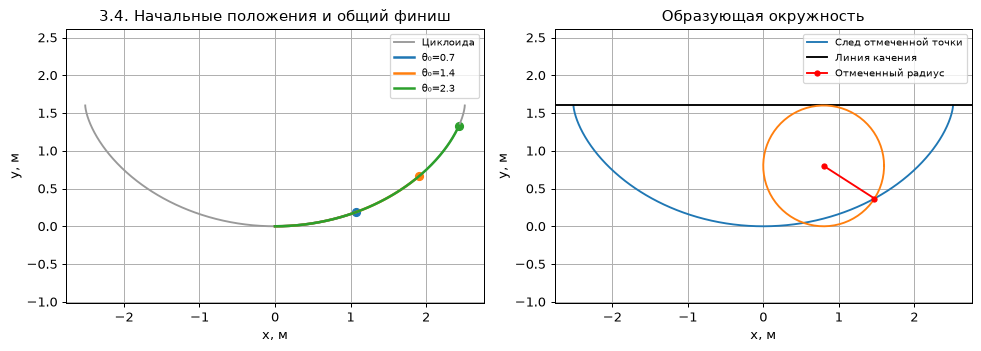

In [5]:
# 3.4. Независимая проверка интеграла времени
a4 = 0.8
omega4 = np.sqrt(g/(4*a4))
T4 = np.pi*np.sqrt(a4/g)
theta04 = np.array([0.7,1.4,2.3])
s04 = 4*a4*np.sin(theta04/2)
for th in theta04:
    h = a4*(1-np.cos(th))
    # Интеграл Абеля: sqrt(a/g) * integral dy/sqrt(y*(h-y)).
    # Алгебраический вес обрабатывает особенности на обоих концах.
    time, err = quad(lambda y: np.sqrt(a4/g),0,h,
                     weight='alg',wvar=(-0.5,-0.5))
    assert np.isclose(time,T4)
    print(f'θ₀={th:.2f}; h={h:.6f} м; T={time:.9f} с')
print(f'Общее время спуска: {T4:.9f} с')
def cycloid(theta):
    return a4*(theta+np.sin(theta)), a4*(1-np.cos(theta))
theta4 = np.linspace(-np.pi,np.pi,600)
fig,axes = plt.subplots(1,2,figsize=(11,4))
axes[0].plot(*cycloid(theta4),color='0.6',label='Циклоида')
for th in theta04:
    branch = np.linspace(0,th,150)
    axes[0].plot(*cycloid(branch),lw=2,label=f'θ₀={th}')
    axes[0].scatter(*cycloid(th),s=40)
axes[0].set(title='3.4. Начальные положения и общий финиш',xlabel='x, м',ylabel='y, м')
axes[0].legend(fontsize=8)
ph = np.linspace(0,2*np.pi,150); th = 1.0
axes[1].plot(*cycloid(theta4),label='След отмеченной точки')
axes[1].axhline(2*a4,color='black',label='Линия качения')
axes[1].plot(a4*th+a4*np.cos(ph),a4+a4*np.sin(ph),color='tab:orange')
px,py = cycloid(th)
axes[1].plot([a4*th,px],[a4,py],'r-o',ms=4,label='Отмеченный радиус')
axes[1].set(title='Образующая окружность',xlabel='x, м',ylabel='y, м'); axes[1].legend(fontsize=8)
for ax in axes: ax.grid(); ax.set_aspect('equal',adjustable='datalim')
finish_figure(fig,'3_4_tautochrone')

fig,axes = plt.subplots(1,2,figsize=(11,4))
for ax in axes:
    ax.plot(*cycloid(theta4),color='0.65')
    ax.set(xlim=(-2.9,2.9),ylim=(-0.2,1.9),xlabel='x, м',ylabel='y, м')
    ax.set_aspect('equal'); ax.grid()
axes[0].set_title('3.4. Одновременный старт из покоя')
balls4 = [axes[0].plot([],[],'o',ms=8,label=f'θ₀={th}')[0] for th in theta04]
axes[0].legend(fontsize=8)
info4 = axes[0].text(0.02,0.96,'',transform=axes[0].transAxes,va='top',fontsize=9)
axes[1].set_title('Качение окружности без скольжения')
axes[1].axhline(2*a4,color='black',lw=1)
circle4, = axes[1].plot([],[],color='tab:orange')
radius4, = axes[1].plot([],[],'r-o',ms=5)
track4, = axes[1].plot([],[],color='crimson',lw=2)
t4 = np.linspace(0,T4,65)
fig.tight_layout()
def update4(k):
    s = s04*np.cos(omega4*t4[k])
    theta = 2*np.arcsin(s/(4*a4))
    for ball,th in zip(balls4,theta):
        xx,yy = cycloid(th); ball.set_data([xx],[yy])
    info4.set_text(f't={t4[k]:.3f} с; T={T4:.3f} с\n'+('Все точки внизу' if k==64 else 'Все точки движутся к нижней точке'))
    th = -np.pi+2*np.pi*k/64
    circle4.set_data(a4*th+a4*np.cos(ph),a4+a4*np.sin(ph))
    xx,yy = cycloid(th)
    radius4.set_data([a4*th,xx],[a4,yy])
    track4.set_data(*cycloid(np.linspace(-np.pi,th,200)))
assert np.allclose(s04*np.cos(omega4*T4),0,atol=1e-14)
anim4 = show_animation(fig,update4,65,'3_4_tautochrone')

### 3.5. Математический маятник

Тангенциальная составляющая силы тяжести $-mg\sin\theta$, поэтому
$$m\ell\ddot\theta=-mg\sin\theta
\quad\Longrightarrow\quad\boxed{\ddot\theta+\frac g\ell\sin\theta=0.}$$
Умножение на $m\ell^2\dot\theta$ даёт интеграл энергии из теории.
В переменных $(\theta,p)$, $p=m\ell^2\dot\theta$:
$$H=\frac{p^2}{2m\ell^2}+mg\ell(1-\cos\theta).$$
Равновесия $(2\pi n,0)$ устойчивы, $((2n+1)\pi,0)$ неустойчивы.

**Малые углы.** При $\theta(0)=A$, $\dot\theta(0)=v_0$:
$$\theta_{\rm lin}(t)=A\cos\omega_0t+\frac{v_0}{\omega_0}\sin\omega_0t.$$
**Точное нелинейное колебание из покоя.** Из энергии
$$\dot\theta^2=4\omega_0^2\left(k^2-\sin^2\frac\theta2\right),
\quad k=\sin(A/2).$$
Подстановка $\sin(\theta/2)=k\sin\varphi$ в четверть периода приводит к
$$\frac T4=\frac1{\omega_0}\int_0^{\pi/2}
\frac{d\varphi}{\sqrt{1-k^2\sin^2\varphi}}.$$
Следовательно,
$$\boxed{T=4K(k^2)/\omega_0},\qquad
\boxed{\theta(t)=2\arcsin[k\operatorname{sn}(K(k^2)-\omega_0t\mid k^2)]}.$$
Функция $\operatorname{sn}$ - эллиптический синус Якоби.
При $A\ll1$ имеем $T=T_{\rm lin}(1+A^2/16+O(A^4))$.

Обозначим $e=E/(mg\ell)$. При $0<e<2$ происходят колебания,
при $e>2$ - вращения. При $e=2$ находятся сепаратриса и верхнее равновесие:
$$\dot\theta=\pm2\omega_0\cos(\theta/2),\quad -\pi\le\theta\le\pi.$$
На сепаратрисе приближение к верхнему положению занимает бесконечное время.
Для вращений при $e>2$ время одного оборота
$$T_{\rm rot}=\frac{4K(2/e)}{\omega_0\sqrt{2e}}.$$
Ниже численно интегрируем и колебания, и вращение, сравниваем с точной
формулой и проверяем сохранение энергии. Углы на графиках отклонения
не сворачиваются по модулю $2\pi$, чтобы были видны полные обороты.

Начальные условия (0.2, 0.0); e=0.019933; дрейф энергии 2.59e-11
Начальные условия (2.6, 0.0); e=1.856889; дрейф энергии 1.35e-09
Начальные условия (0.0, np.float64(7.203811491148279)); e=2.645000; дрейф энергии 4.97e-09
A=0.2: T=2.011093371 с; T/Tлинейный=1.002506
A=2.6: T=3.494912846 с; T/Tлинейный=1.742172


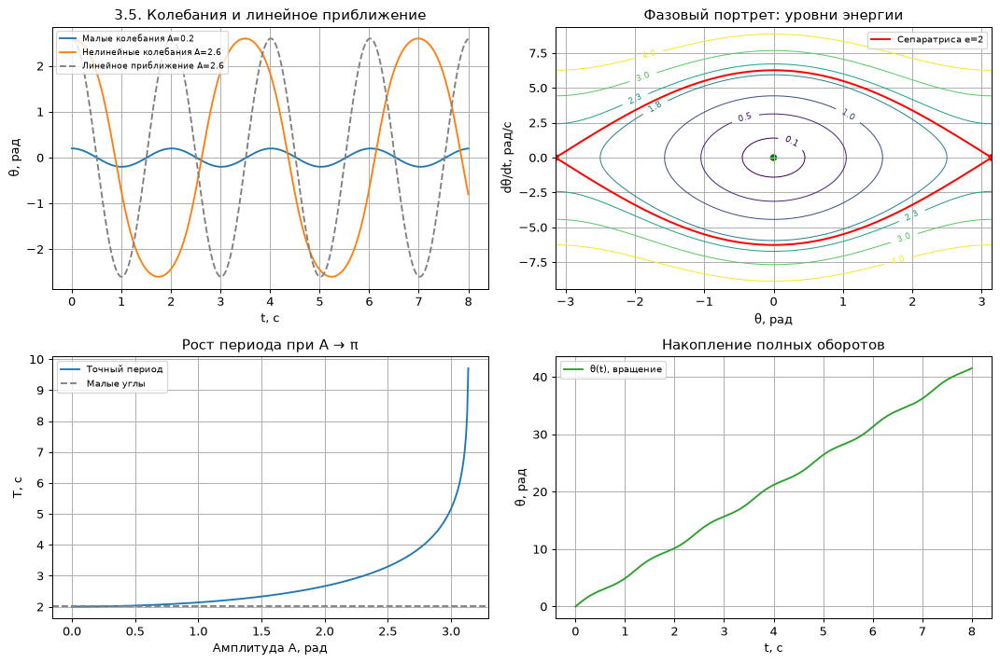

In [6]:
# 3.5. Решение ОДУ и содержательные проверки
ell5 = 1.0
omega5 = np.sqrt(g/ell5)
Tlin5 = 2*np.pi/omega5
t5 = np.linspace(0,8,1800)
initial5 = [(0.2,0.0),(2.6,0.0),(0.0,2.3*omega5)]
labels5 = ['Малые колебания A=0.2', 'Нелинейные колебания A=2.6', 'Вращение']
solutions5 = []
for initial in initial5:
    sol = solve_ivp(lambda t,z:[z[1],-omega5**2*np.sin(z[0])],
                    (0,t5[-1]),initial,t_eval=t5,rtol=2e-10,atol=2e-12)
    assert sol.success
    energy = 0.5*(sol.y[1]/omega5)**2+1-np.cos(sol.y[0])
    drift = np.max(abs(energy-energy[0]))
    assert drift < 1e-7
    print(f'Начальные условия {initial}; e={energy[0]:.6f}; дрейф энергии {drift:.2e}')
    solutions5.append(sol.y)
for A, numerical in zip([0.2,2.6],solutions5[:2]):
    parameter = np.sin(A/2)**2
    sn,cn,dn,am = ellipj(ellipk(parameter)-omega5*t5,parameter)
    exact = 2*np.arcsin(np.sqrt(parameter)*sn)
    assert np.max(abs(exact-numerical[0]))<1e-7
    print(f'A={A}: T={4*ellipk(parameter)/omega5:.9f} с; T/Tлинейный={2*ellipk(parameter)/np.pi:.6f}')

fig,axes = plt.subplots(2,2,figsize=(12,8))
axes = axes.ravel()
for z,label in zip(solutions5[:2],labels5[:2]): axes[0].plot(t5,z[0],label=label)
axes[0].plot(t5,2.6*np.cos(omega5*t5),'--',color='0.5',label='Линейное приближение A=2.6')
axes[0].set(xlabel='t, с',ylabel='θ, рад',title='3.5. Колебания и линейное приближение')
axes[0].legend(fontsize=7); axes[0].grid()
th = np.linspace(-np.pi,np.pi,300)
vel = np.linspace(-3*omega5,3*omega5,300)
Q,V = np.meshgrid(th,vel)
energy_grid = 0.5*(V/omega5)**2+1-np.cos(Q)
contours = axes[1].contour(Q,V,energy_grid,levels=[0.1,0.5,1,1.8,2.3,3,4],linewidths=0.8)
axes[1].clabel(contours,fontsize=7)
for sign in [-1,1]: axes[1].plot(th,sign*2*omega5*np.cos(th/2),'r',lw=1.6)
axes[1].plot([],[],'r',label='Сепаратриса e=2')
axes[1].scatter([0,-np.pi,np.pi],[0,0,0],c=['green','red','red'],s=25)
axes[1].set(xlabel='θ, рад',ylabel='dθ/dt, рад/с',title='Фазовый портрет: уровни энергии')
axes[1].legend(fontsize=8); axes[1].grid()
amplitudes = np.linspace(0,np.pi-0.004,350)
axes[2].plot(amplitudes,4*ellipk(np.sin(amplitudes/2)**2)/omega5,label='Точный период')
axes[2].axhline(Tlin5,ls='--',color='0.5',label='Малые углы')
axes[2].set(xlabel='Амплитуда A, рад',ylabel='T, с',title='Рост периода при A → π')
axes[2].grid(); axes[2].legend(fontsize=8)
axes[3].plot(t5,solutions5[2][0],color='tab:green',label='θ(t), вращение')
axes[3].set(xlabel='t, с',ylabel='θ, рад',title='Накопление полных оборотов')
axes[3].grid(); axes[3].legend(fontsize=8)
finish_figure(fig,'3_5_pendulum')

fig,axes = plt.subplots(1,2,figsize=(11,5))
axes[0].set(xlim=(-1.3,1.3),ylim=(-1.3,1.3),xlabel='x, м',ylabel='y, м',title='3.5. Три режима маятника')
axes[0].set_aspect('equal'); axes[0].grid(); axes[0].plot([0],[0],'ko')
for sign in [-1,1]: axes[1].plot(th,sign*2*omega5*np.cos(th/2),'r--',lw=0.8)
axes[1].set(xlim=(-np.pi,np.pi),ylim=(-3*omega5,3*omega5),xlabel='θ mod 2π',ylabel='dθ/dt, рад/с',title='Синхронная фазовая плоскость')
axes[1].grid()
pendulum_artists5 = []
for color,label in zip(['tab:blue','tab:orange','tab:green'],labels5):
    rod, = axes[0].plot([],[],'o-',color=color,lw=2,label=label)
    trace, = axes[1].plot([],[],color=color,lw=1)
    dot, = axes[1].plot([],[],'o',color=color,ms=6)
    pendulum_artists5.append((rod,trace,dot))
axes[0].legend(loc='upper left',fontsize=7)
caption5 = fig.suptitle('')
fig.tight_layout(rect=(0,0,1,0.93))
def update5(k):
    for z,(rod,trace,dot) in zip(solutions5,pendulum_artists5):
        angle,velocity = z[:,k]
        rod.set_data([0,ell5*np.sin(angle)],[0,-ell5*np.cos(angle)])
        wrapped = (z[0,:k+1]+np.pi)%(2*np.pi)-np.pi
        cut = np.r_[False,np.abs(np.diff(wrapped))>np.pi]
        # Разрываем линию при пересечении края фазового цилиндра.
        trace.set_data(np.where(cut,np.nan,wrapped),z[1,:k+1])
        dot.set_data([(angle+np.pi)%(2*np.pi)-np.pi],[velocity])
    caption5.set_text(f't={t5[k]:.2f} с; g={g} м/с²; ℓ={ell5} м; T малых колебаний={Tlin5:.3f} с')
anim5 = show_animation(fig,update5,np.linspace(0,len(t5)-1,90,dtype=int),'3_5_pendulum')

### Проверка полноты работы

Выполнены задания **3.1–3.5**. Для каждого приведены постановка,
аналитический вывод, статический рисунок и управляемая анимация `FuncAnimation`.
Вычислительные проверки включают закон энергии при равномерном спуске,
замыкание периодической бильярдной орбиты, баланс сил элемента цепи,
равенство времён спуска по циклоиде и сравнение численного маятника
с эллиптическим решением. Рисунки и автономные HTML сохраняются в `output/prac3`.